<a href="https://colab.research.google.com/github/Joyengineer3/DS2002-OSEI/blob/main/Homework_assignment_1_J_O.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')
print(" Libraries loaded!")

 Libraries loaded!


In [ ]:
import pandas as pd
import numpy as np
np.random.seed(42)
# 3 production lines × 5 days × 20 readings = 300 rows
production_lines = ['L1', 'L2', 'L3']
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri']
records = []
for day in days:
    for line in production_lines:
        for _ in range(20):
            if line == 'L1':
                torque = np.random.normal(loc=98, scale=3)   # Slightly below target
            elif line == 'L2':
                torque = np.random.normal(loc=101, scale=5)  # On target, most variable
            elif line == 'L3':
                torque = np.random.normal(loc=95, scale=2)   # Below target, tightest
            records.append({
                'day': day,
                'production_line': line,
                'torque_Nm': round(torque, 4)
            })
df = pd.DataFrame(records)
print(df.shape)

(300, 3)


In [ ]:
# Overall summary statistics for torque
summary_stats = df['torque_Nm'].describe().round(4)
print(summary_stats)

count    300.0000
mean      97.9296
std        4.1822
min       84.7937
25%       94.9219
50%       97.0479
75%      100.4383
max      120.2637
Name: torque_Nm, dtype: float64


In [ ]:
# Compute summary statistics grouped by production line
line_stats = df.groupby('production_line')['torque_Nm'].describe().round(4)
print(line_stats)

                 count      mean     std      min      25%       50%  \
production_line                                                        
L1               100.0   97.7621  2.9340  90.1408  95.4518   97.7186   
L2               100.0  100.8357  4.9128  84.7937  97.8936  101.3792   
L3               100.0   95.1910  1.9869  90.9497  93.7402   95.1778   

                      75%       max  
production_line                      
L1                99.7897  104.5714  
L2               103.5705  120.2637  
L3                96.4836  100.4403  


In [ ]:
print(df.dtypes)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

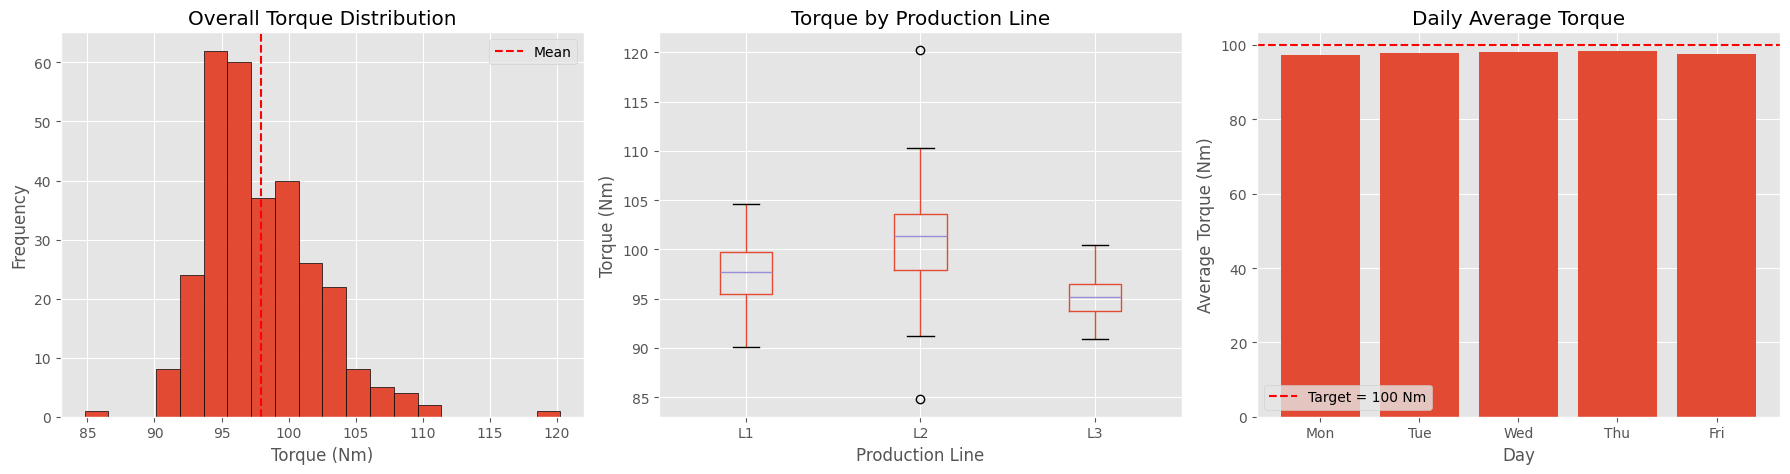

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram - Overall Torque Distribution
axes[0].hist(df['torque_Nm'], bins=20, edgecolor='black')
axes[0].axvline(df['torque_Nm'].mean(), color='red', linestyle='--',
                label='Mean')
axes[0].set_title('Overall Torque Distribution')
axes[0].set_xlabel('Torque (Nm)')
axes[0].set_ylabel('Frequency')
axes[0].legend()


# 2. Boxplot - Torque by Production Line
df.boxplot(column='torque_Nm', by='production_line', ax=axes[1])
axes[1].set_title('Torque by Production Line')
axes[1].set_xlabel('Production Line')
axes[1].set_ylabel('Torque (Nm)')


# 3. Bar Chart - Daily Average Torque
day_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri']
daily_avg = df.groupby('day')['torque_Nm'].mean().reindex(day_order)

axes[2].bar(daily_avg.index, daily_avg.values)
axes[2].axhline(100, color='red', linestyle='--', label='Target = 100 Nm')
axes[2].set_title('Daily Average Torque')
axes[2].set_xlabel('Day')
axes[2].set_ylabel('Average Torque (Nm)')
axes[2].legend()


plt.suptitle('')
plt.tight_layout()
plt.show()